# №2 СӨЖ. Терең оқытудағы гиперпараметрлерді оңтайландыру
**Бастапқы жоба:** Muhammet Zahit Aydın, *CNN Hyperparameter Tuning*, Kaggle.
**Мақсат:** CNN архитектуралары мен оқыту параметрлерінің цифрларды тану дәлдігіне әсерін зерттеу.
**Дереккөз:** Kaggle Digit Recognizer. Бұл файл — автор жұмысының қазақша бейімделуі; бастапқы ноутбуктегі нәтижелер автордың сақталған есептеу нәтижелері.


## 1. Деректерді оқу


In [ ]:
import pandas as pd
from google.colab import files
from io import BytesIO

print("train.csv және test.csv файлдарын бірге жүктеңіз")
uploaded = files.upload()
train = pd.read_csv(BytesIO(uploaded["train.csv"]))
test = pd.read_csv(BytesIO(uploaded["test.csv"]))
train.head(5)


/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


<AxesSubplot:xlabel='label', ylabel='count'>

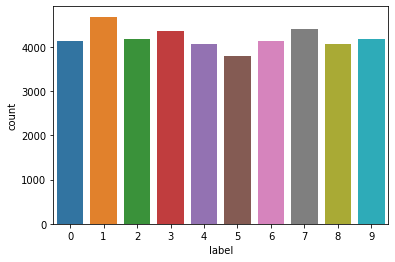

In [2]:
import seaborn as sns
X = train.drop(labels=["label"], axis = 1)
y = train["label"]
sns.countplot(y)

## 2. Деректерді қалыптандыру


Пиксель мәндерін 0–1 аралығына келтіру оқытуды тұрақтандыруға көмектеседі.


In [3]:
X = X / 255.0
test = test / 255.0

In [4]:
X = X.values.reshape(-1, 28, 28, 1)
test = test.values.reshape(-1, 28, 28, 1)

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

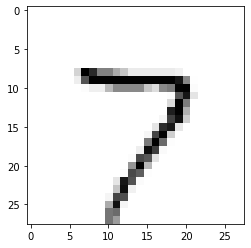

In [6]:
import matplotlib.pyplot as plt
plt.imshow(X_train[15][:, :, 0], cmap = "Greys")

## 3. Деректерді жасанды кеңейту (аугментация)


Оқыту жиынын әртүрлі ету үшін суреттерді аздап бұру, масштабтау және жылжыту қолданылады.


In [7]:
from tensorflow import keras
datagen = keras.preprocessing.image.ImageDataGenerator( rotation_range= 10, zoom_range=0.1, 
                                                       width_shift_range=0.1, height_shift_range=0.1)

datagen.fit(X_train)
y_train_c = keras.utils.to_categorical(y_train)
y_test_c = keras.utils.to_categorical(y_test)
train_data = datagen.flow(x = X_train, y = y_train_c, batch_size=64)
test_data = datagen.flow(x = X_test, y = y_test_c, batch_size = 64)

## 4. CNN модельдерін оқыту


Алдымен CNN-нің үш архитектурасын салыстырамыз, содан кейін жақсы нәтиже бергенін зерттейміз.


In [8]:
from keras import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from keras.optimizers import SGD, RMSprop, Adam, Adadelta, Adagrad, Adamax, Nadam, Ftrl

input_shape = (28, 28, 1)
def cnn1():
    return Sequential([
        Conv2D(8, kernel_size=(3, 3), activation='relu',padding='same',input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Conv2D(16, kernel_size=(5, 5), activation='relu'),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Flatten(),
        Dense(120, activation='relu'),
        Dense(84, activation='relu'),
        Dense(10, activation='softmax')
    ])

def cnn2():
    return Sequential([
        Conv2D(32, kernel_size=(3, 3), activation='relu',input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Conv2D(64, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Conv2D(128, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

def cnn3():
    return Sequential([
        Conv2D(16, kernel_size=(3, 3), activation='relu',padding='same',input_shape=input_shape),
        Conv2D(16, kernel_size=(3, 3), activation='relu',padding='same'),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2),strides=2),
        Flatten(),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])

In [9]:
model = cnn1()
model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
history = model.fit(train_data ,epochs=3, validation_data=test_data, verbose=2)

Epoch 1/3
525/525 - 19s - loss: 0.5530 - accuracy: 0.8256 - val_loss: 0.2339 - val_accuracy: 0.9270
Epoch 2/3
525/525 - 11s - loss: 0.1802 - accuracy: 0.9445 - val_loss: 0.1305 - val_accuracy: 0.9596
Epoch 3/3
525/525 - 11s - loss: 0.1263 - accuracy: 0.9605 - val_loss: 0.0993 - val_accuracy: 0.9696


Деректер генераторын қолдану есептеу уақытына әсер етеді. Бастапқы тәжірибеде массивке ауыстырылған деректердің орындалуы тезірек болған.


In [10]:
import numpy as np
train_data = datagen.flow(x = X_train, y = y_train_c, batch_size=1)
test_data = datagen.flow(x = X_test, y = y_test_c, batch_size = 1)
def get_array_from_datagen(train_generator):
  x=[]
  y=[]
  train_generator.reset()
  for i in range(train_generator.__len__()):
    a,b=train_generator.next()
    x.append(a)
    y.append(b)
  x=np.array(x)
  y=np.array(y)
  print(x.shape)
  print(y.shape)
  return x,y

X_train_2, y_train_2 = get_array_from_datagen(train_data)
X_test_2, y_test_2 = get_array_from_datagen(test_data)

X_train_2 = X_train_2.reshape(-1, 28, 28, 1)
y_train_2 = y_train_2.reshape(-1, 10)

X_test_2 = X_test_2.reshape(-1, 28, 28, 1)
y_test_2 = y_test_2.reshape(-1, 10)

X_train_2.shape, y_train_2.shape

(33600, 1, 28, 28, 1)
(33600, 1, 10)
(8400, 1, 28, 28, 1)
(8400, 1, 10)


((33600, 28, 28, 1), (33600, 10))

In [11]:
model = cnn1()
model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2 ,epochs=3, validation_data=(X_test_2, y_test_2), verbose=2)

Epoch 1/3
1050/1050 - 4s - loss: 0.4174 - accuracy: 0.8673 - val_loss: 0.1939 - val_accuracy: 0.9393
Epoch 2/3
1050/1050 - 3s - loss: 0.1444 - accuracy: 0.9553 - val_loss: 0.1198 - val_accuracy: 0.9608
Epoch 3/3
1050/1050 - 3s - loss: 0.1010 - accuracy: 0.9683 - val_loss: 0.1277 - val_accuracy: 0.9611


Алдыңғы тәжірибе массив форматындағы деректердің жылдамырақ өңделгенін көрсетті. Төменде CNN архитектуралары салыстырылады.


In [12]:
import matplotlib.pyplot as plt
def plot_history(history):
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('model accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()
    # summarize history for loss
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('model loss')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['train', 'test'], loc='upper left')
    plt.show()

In [13]:
model = cnn1()
model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2 ,epochs=25, validation_data=(X_test_2, y_test_2), verbose=2)

Epoch 1/25
1050/1050 - 4s - loss: 0.4338 - accuracy: 0.8631 - val_loss: 0.1962 - val_accuracy: 0.9398
Epoch 2/25
1050/1050 - 3s - loss: 0.1469 - accuracy: 0.9542 - val_loss: 0.1162 - val_accuracy: 0.9643
Epoch 3/25
1050/1050 - 3s - loss: 0.1039 - accuracy: 0.9681 - val_loss: 0.1078 - val_accuracy: 0.9693
Epoch 4/25
1050/1050 - 3s - loss: 0.0774 - accuracy: 0.9757 - val_loss: 0.1116 - val_accuracy: 0.9640
Epoch 5/25
1050/1050 - 3s - loss: 0.0611 - accuracy: 0.9805 - val_loss: 0.0908 - val_accuracy: 0.9744
Epoch 6/25
1050/1050 - 3s - loss: 0.0507 - accuracy: 0.9826 - val_loss: 0.0816 - val_accuracy: 0.9748
Epoch 7/25
1050/1050 - 3s - loss: 0.0419 - accuracy: 0.9860 - val_loss: 0.0967 - val_accuracy: 0.9712
Epoch 8/25
1050/1050 - 2s - loss: 0.0354 - accuracy: 0.9879 - val_loss: 0.0790 - val_accuracy: 0.9767
Epoch 9/25
1050/1050 - 2s - loss: 0.0265 - accuracy: 0.9910 - val_loss: 0.1012 - val_accuracy: 0.9719
Epoch 10/25
1050/1050 - 3s - loss: 0.0261 - accuracy: 0.9909 - val_loss: 0.0778 - 

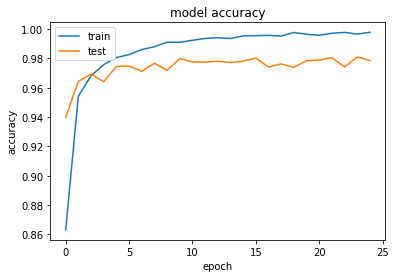

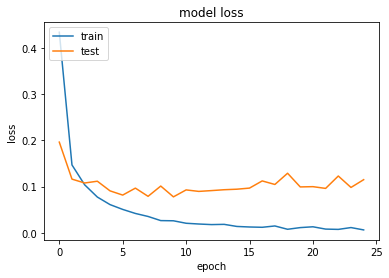

In [14]:
plot_history(history)

In [15]:
model = cnn2()
model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2 ,epochs=25, validation_data=(X_test_2, y_test_2), verbose=2)

Epoch 1/25
1050/1050 - 4s - loss: 0.4703 - accuracy: 0.8495 - val_loss: 0.2242 - val_accuracy: 0.9270
Epoch 2/25
1050/1050 - 3s - loss: 0.1824 - accuracy: 0.9409 - val_loss: 0.1465 - val_accuracy: 0.9540
Epoch 3/25
1050/1050 - 3s - loss: 0.1298 - accuracy: 0.9580 - val_loss: 0.1332 - val_accuracy: 0.9560
Epoch 4/25
1050/1050 - 3s - loss: 0.0992 - accuracy: 0.9677 - val_loss: 0.1186 - val_accuracy: 0.9621
Epoch 5/25
1050/1050 - 3s - loss: 0.0827 - accuracy: 0.9721 - val_loss: 0.1061 - val_accuracy: 0.9656
Epoch 6/25
1050/1050 - 3s - loss: 0.0628 - accuracy: 0.9790 - val_loss: 0.1158 - val_accuracy: 0.9658
Epoch 7/25
1050/1050 - 3s - loss: 0.0525 - accuracy: 0.9820 - val_loss: 0.1054 - val_accuracy: 0.9687
Epoch 8/25
1050/1050 - 3s - loss: 0.0418 - accuracy: 0.9860 - val_loss: 0.1152 - val_accuracy: 0.9677
Epoch 9/25
1050/1050 - 3s - loss: 0.0373 - accuracy: 0.9871 - val_loss: 0.1122 - val_accuracy: 0.9685
Epoch 10/25
1050/1050 - 3s - loss: 0.0319 - accuracy: 0.9890 - val_loss: 0.1295 - 

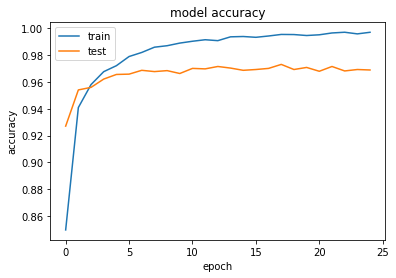

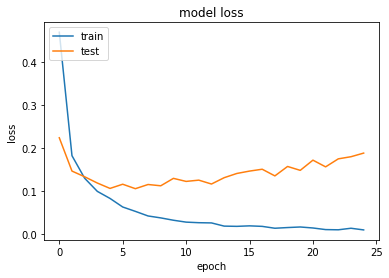

In [16]:
plot_history(history)

In [17]:
model = cnn3()
model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2 ,epochs=25, validation_data=(X_test_2, y_test_2), verbose=2)

Epoch 1/25
1050/1050 - 4s - loss: 0.2683 - accuracy: 0.9150 - val_loss: 0.1147 - val_accuracy: 0.9644
Epoch 2/25
1050/1050 - 3s - loss: 0.0762 - accuracy: 0.9764 - val_loss: 0.0720 - val_accuracy: 0.9767
Epoch 3/25
1050/1050 - 3s - loss: 0.0466 - accuracy: 0.9845 - val_loss: 0.0940 - val_accuracy: 0.9713
Epoch 4/25
1050/1050 - 3s - loss: 0.0346 - accuracy: 0.9887 - val_loss: 0.0659 - val_accuracy: 0.9819
Epoch 5/25
1050/1050 - 3s - loss: 0.0259 - accuracy: 0.9918 - val_loss: 0.0649 - val_accuracy: 0.9813
Epoch 6/25
1050/1050 - 3s - loss: 0.0205 - accuracy: 0.9931 - val_loss: 0.0681 - val_accuracy: 0.9827
Epoch 7/25
1050/1050 - 3s - loss: 0.0197 - accuracy: 0.9935 - val_loss: 0.0596 - val_accuracy: 0.9844
Epoch 8/25
1050/1050 - 4s - loss: 0.0131 - accuracy: 0.9956 - val_loss: 0.0591 - val_accuracy: 0.9848
Epoch 9/25
1050/1050 - 3s - loss: 0.0131 - accuracy: 0.9954 - val_loss: 0.0622 - val_accuracy: 0.9836
Epoch 10/25
1050/1050 - 3s - loss: 0.0118 - accuracy: 0.9959 - val_loss: 0.0644 - 

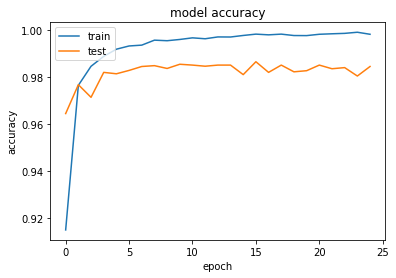

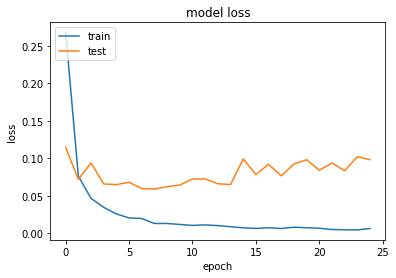

In [18]:
plot_history(history)

Алғашқы тәжірибе негізінде CNN-3 моделі әрі қарай зерттеуге алынған.


## 5. Пакет өлшемін (batch size) таңдау


In [19]:
import gc
best_accuracy = 0
best_batch_size = -1
for batch_size in [32, 64, 128, 256]:
    model = cnn3()
    model.compile(optimizer="Adam", loss=["categorical_crossentropy"], metrics = ["accuracy"])
    history = model.fit(X_train_2, y_train_2 ,epochs=10, batch_size = batch_size, validation_data=(X_test_2, y_test_2), verbose=0)
    acc = history.history["val_accuracy"][-1]
    if acc > best_accuracy:
        best_accuracy = acc
        best_batch_size = batch_size
    print(batch_size, acc)
    gc.collect() # Clear RAM
print("\nBEST -> ", best_batch_size, best_accuracy)

32 0.9803571701049805
64 0.9821428656578064
128 0.9846428632736206
256 0.9838095307350159

BEST ->  128 0.9846428632736206


Бастапқы автор 32 пакет өлшемін таңдаған. Алайда сақталған есептеу нәтижесінде ең жоғары валидациялық дәлдік 128 пакет өлшемінде алынған. Бұл айырмашылық талдауда ескеріледі.


## 6. Оңтайландырғышты таңдау


ReduceLROnPlateau оқыту барысындағы валидациялық көрсеткішке қарай learning rate параметрін азайтады.


In [20]:
learning_rate_reduction = keras.callbacks.ReduceLROnPlateau(
    monitor = "val_accuracy",
    factor = 0.5,
    patience = 3,
    verbose = 0,
    min_lr = 0.00001
)

In [21]:
learning_rate = [0.01, 0.001, 0.0001]
momentum = [0, 0.2, 0.4, 0.6, 0.8, 0.99]
nesterov = [True, False]
best_accuracy = 0
best_sgd_params = {"learning_rate" : 0, "momentum" : 0, "nesterov" : True}
for l_rate in learning_rate:
  for m in momentum:
    for n in nesterov:
      
      optimizer = SGD(learning_rate=l_rate, momentum=m, nesterov=n)
      
      model = cnn3()
      model.compile(optimizer=optimizer, loss=["categorical_crossentropy"], metrics = ["accuracy"])
      
      history = model.fit(X_train_2, y_train_2, batch_size = 32, epochs=10, 
                         validation_data=(X_test_2, y_test_2), verbose=0, callbacks = [learning_rate_reduction])
      acc = history.history["val_accuracy"][-1]
      if acc > best_accuracy:
        best_sgd_params["learning_rate"] = l_rate
        best_sgd_params["momentum"] = m
        best_sgd_params["nesterov"] = n
        best_accuracy = acc
      print("SGD : "+ f"{l_rate}/{m}/{n} -> ", acc)
      gc.collect() # Clear RAM
print("\n Best -> " + str(best_sgd_params) + " -> " + str(best_accuracy))

SGD : 0.01/0/True ->  0.9697619080543518
SGD : 0.01/0/False ->  0.9690476059913635
SGD : 0.01/0.2/True ->  0.9702380895614624
SGD : 0.01/0.2/False ->  0.9700000286102295
SGD : 0.01/0.4/True ->  0.9720237851142883
SGD : 0.01/0.4/False ->  0.9719047546386719
SGD : 0.01/0.6/True ->  0.973809540271759
SGD : 0.01/0.6/False ->  0.9778571724891663
SGD : 0.01/0.8/True ->  0.9814285635948181
SGD : 0.01/0.8/False ->  0.9807142615318298
SGD : 0.01/0.99/True ->  0.11166666448116302
SGD : 0.01/0.99/False ->  0.8490476012229919
SGD : 0.001/0/True ->  0.9092857241630554
SGD : 0.001/0/False ->  0.9148809313774109
SGD : 0.001/0.2/True ->  0.9325000047683716
SGD : 0.001/0.2/False ->  0.9370238184928894
SGD : 0.001/0.4/True ->  0.948452353477478
SGD : 0.001/0.4/False ->  0.9376190304756165
SGD : 0.001/0.6/True ->  0.9540476202964783
SGD : 0.001/0.6/False ->  0.954880952835083
SGD : 0.001/0.8/True ->  0.9626190662384033
SGD : 0.001/0.8/False ->  0.9608333110809326
SGD : 0.001/0.99/True ->  0.9861904978752

In [22]:
learning_rate = [0.01, 0.001, 0.0001]
momentum = [0.8, 0]
centered = [True, False]
epsilon = [10e-7, 10e-6, 10e-8]
rho = [0.9, 0.45]
best_accuracy = 0
best_rms_params = {"learning_rate" : 0, "momentum" : 0, "centered" : False, "epsilon": 0, "rho" : 0}
for l_rate in learning_rate:
  for m in momentum:
    for c in centered:
        for e in epsilon:
            for r in rho:
              optimizer = RMSprop(learning_rate=l_rate, momentum=m, centered=c, epsilon = e, rho = r)

              model = cnn3()
              model.compile(optimizer=optimizer, loss=["categorical_crossentropy"], metrics = ["accuracy"])

              history = model.fit(X_train_2, y_train_2, batch_size = 32, epochs=10, 
                                 validation_data=(X_test_2, y_test_2), verbose=0, callbacks = [learning_rate_reduction])
              acc = history.history["val_accuracy"][-1]
              if acc > best_accuracy:
                best_rms_params["learning_rate"] = l_rate
                best_rms_params["momentum"] = m
                best_rms_params["centered"] = c
                best_rms_params["epsilon"] = e
                best_rms_params["rho"] = r
                best_accuracy = acc
              print("RMSProp : "+ f"{l_rate}/{m}/{c}/{e}/{r} -> ", acc)
              gc.collect() # Clear RAM
      
      
print("\n Best -> " + str(best_rms_params) + " -> " + str(best_accuracy))

RMSProp : 0.01/0.8/True/1e-06/0.9 ->  0.10773809254169464
RMSProp : 0.01/0.8/True/1e-06/0.45 ->  0.10773809254169464
RMSProp : 0.01/0.8/True/1e-05/0.9 ->  0.11166666448116302
RMSProp : 0.01/0.8/True/1e-05/0.45 ->  0.11166666448116302
RMSProp : 0.01/0.8/True/1e-07/0.9 ->  0.10190476477146149
RMSProp : 0.01/0.8/True/1e-07/0.45 ->  0.11166666448116302
RMSProp : 0.01/0.8/False/1e-06/0.9 ->  0.10773809254169464
RMSProp : 0.01/0.8/False/1e-06/0.45 ->  0.11166666448116302
RMSProp : 0.01/0.8/False/1e-05/0.9 ->  0.10273809731006622
RMSProp : 0.01/0.8/False/1e-05/0.45 ->  0.11166666448116302
RMSProp : 0.01/0.8/False/1e-07/0.9 ->  0.11166666448116302
RMSProp : 0.01/0.8/False/1e-07/0.45 ->  0.11166666448116302
RMSProp : 0.01/0/True/1e-06/0.9 ->  0.9677380919456482
RMSProp : 0.01/0/True/1e-06/0.45 ->  0.5657142996788025
RMSProp : 0.01/0/True/1e-05/0.9 ->  0.11166666448116302
RMSProp : 0.01/0/True/1e-05/0.45 ->  0.10190476477146149
RMSProp : 0.01/0/True/1e-07/0.9 ->  0.960357129573822
RMSProp : 0.01

In [23]:
learning_rate = [0.01, 0.001, 0.0001]
beta_1 = [0.9, 0.99]
beta_2 = [0.9, 0.99]
epsilon = [1e-7, 1e-5, 1e-3]
amsgrad = [False, True]
best_accuracy = 0
best_adam_params = {"learning_rate" : 0, "beta_1" : 0, "beta_2" : 0, "epsilon" : 0, "amsgrad" : True}
for l in learning_rate:
    for b1 in beta_1:
        for b2 in beta_2:
            for e in epsilon:
                for a in amsgrad:
                  optimizer = Adam(learning_rate=l, beta_1 = b1, beta_2 = b2, epsilon = e, amsgrad = a)

                  model = cnn3()
                  model.compile(optimizer=optimizer, loss=["categorical_crossentropy"], metrics = ["accuracy"])

                  history = model.fit(X_train_2, y_train_2, batch_size = 32, epochs=10, 
                                     validation_data=(X_test_2, y_test_2), verbose=0, callbacks = [learning_rate_reduction])
                  acc = history.history["val_accuracy"][-1]
                  if acc > best_accuracy:
                    best_adam_params["learning_rate"] = l
                    best_adam_params["beta_1"] = b1
                    best_adam_params["beta_2"] = b2
                    best_adam_params["epsilon"] = e
                    best_adam_params["amsgrad"] = a
                    best_accuracy = acc
                  print("Adam : "+ f"{l}/{b1}/{b2}/{e}/{a} -> ", acc)
                  gc.collect() # Clear RAM
      
      
print("\n Best -> " + str(best_adam_params) + " -> " + str(best_accuracy))

Adam : 0.01/0.9/0.9/1e-07/False ->  0.11166666448116302
Adam : 0.01/0.9/0.9/1e-07/True ->  0.9754762053489685
Adam : 0.01/0.9/0.9/1e-05/False ->  0.9539285898208618
Adam : 0.01/0.9/0.9/1e-05/True ->  0.9788095355033875
Adam : 0.01/0.9/0.9/0.001/False ->  0.977738082408905
Adam : 0.01/0.9/0.9/0.001/True ->  0.9835714101791382
Adam : 0.01/0.9/0.99/1e-07/False ->  0.11166666448116302
Adam : 0.01/0.9/0.99/1e-07/True ->  0.11166666448116302
Adam : 0.01/0.9/0.99/1e-05/False ->  0.9482142925262451
Adam : 0.01/0.9/0.99/1e-05/True ->  0.9708333611488342
Adam : 0.01/0.9/0.99/0.001/False ->  0.9760714173316956
Adam : 0.01/0.9/0.99/0.001/True ->  0.9867857098579407
Adam : 0.01/0.99/0.9/1e-07/False ->  0.10214285552501678
Adam : 0.01/0.99/0.9/1e-07/True ->  0.9726190567016602
Adam : 0.01/0.99/0.9/1e-05/False ->  0.8072618842124939
Adam : 0.01/0.99/0.9/1e-05/True ->  0.11166666448116302
Adam : 0.01/0.99/0.9/0.001/False ->  0.9560714364051819
Adam : 0.01/0.99/0.9/0.001/True ->  0.9825000166893005
Ada

In [24]:
accuricies = {}
params = {"SGD" : best_sgd_params, "Adam": best_adam_params, "RMSprop": best_rms_params}

In [25]:
p = best_sgd_params
optimizer = SGD(learning_rate = p["learning_rate"], momentum = p["momentum"], nesterov = p["nesterov"])
model = cnn3()
model.compile(optimizer = optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2, epochs = 25, batch_size = 32, callbacks = [learning_rate_reduction], validation_data=(X_test_2, y_test_2))
accuricies["SGD"] = history.history["val_accuracy"][-1]

Epoch 1/25
1050/1050 [==============================] - 5s 4ms/step - loss: 1.2617 - accuracy: 0.5626 - val_loss: 0.1616 - val_accuracy: 0.9499
Epoch 2/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.1243 - accuracy: 0.9593 - val_loss: 0.1015 - val_accuracy: 0.9692
Epoch 3/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0735 - accuracy: 0.9765 - val_loss: 0.0989 - val_accuracy: 0.9685
Epoch 4/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0513 - accuracy: 0.9831 - val_loss: 0.0780 - val_accuracy: 0.9749
Epoch 5/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0353 - accuracy: 0.9885 - val_loss: 0.0792 - val_accuracy: 0.9800
Epoch 6/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0253 - accuracy: 0.9921 - val_loss: 0.0905 - val_accuracy: 0.9780
Epoch 7/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0237 - accuracy: 0.9926 - val_loss: 0.0713 - val_accuracy:

In [26]:
p = best_rms_params
optimizer = RMSprop(learning_rate = p["learning_rate"], momentum = p["momentum"], 
                    centered = p["centered"], epsilon = p["epsilon"], rho=p["rho"])
model = cnn3()
model.compile(optimizer = optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2, epochs = 25, batch_size = 32, callbacks = [learning_rate_reduction], validation_data=(X_test_2, y_test_2))
accuricies["RMSprop"] = history.history["val_accuracy"][-1]

Epoch 1/25
1050/1050 [==============================] - 5s 4ms/step - loss: 0.5160 - accuracy: 0.8280 - val_loss: 0.1179 - val_accuracy: 0.9670
Epoch 2/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0949 - accuracy: 0.9711 - val_loss: 0.0754 - val_accuracy: 0.9808
Epoch 3/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0645 - accuracy: 0.9814 - val_loss: 0.1184 - val_accuracy: 0.9685
Epoch 4/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0529 - accuracy: 0.9852 - val_loss: 0.1046 - val_accuracy: 0.9774
Epoch 5/25
1050/1050 [==============================] - 5s 5ms/step - loss: 0.0454 - accuracy: 0.9876 - val_loss: 0.0972 - val_accuracy: 0.9763
Epoch 6/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0155 - accuracy: 0.9945 - val_loss: 0.0615 - val_accuracy: 0.9865
Epoch 7/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0046 - accuracy: 0.9984 - val_loss: 0.1051 - val_accuracy:

In [27]:
p = best_adam_params
optimizer = Adam(learning_rate = p["learning_rate"], beta_1 = p["beta_1"], beta_2 = p["beta_2"],
                 epsilon = p["epsilon"], amsgrad=p["amsgrad"])
model = cnn3()
model.compile(optimizer = optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])
history = model.fit(X_train_2, y_train_2, epochs = 25, batch_size = 32, callbacks = [learning_rate_reduction], validation_data=(X_test_2, y_test_2))
accuricies["Adam"] = history.history["val_accuracy"][-1]

Epoch 1/25
1050/1050 [==============================] - 5s 4ms/step - loss: 0.5491 - accuracy: 0.8158 - val_loss: 0.0956 - val_accuracy: 0.9699
Epoch 2/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0828 - accuracy: 0.9743 - val_loss: 0.0880 - val_accuracy: 0.9737
Epoch 3/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0475 - accuracy: 0.9851 - val_loss: 0.0604 - val_accuracy: 0.9830
Epoch 4/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0291 - accuracy: 0.9901 - val_loss: 0.0520 - val_accuracy: 0.9845
Epoch 5/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0205 - accuracy: 0.9935 - val_loss: 0.0591 - val_accuracy: 0.9837
Epoch 6/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0165 - accuracy: 0.9943 - val_loss: 0.0777 - val_accuracy: 0.9823
Epoch 7/25
1050/1050 [==============================] - 4s 4ms/step - loss: 0.0142 - accuracy: 0.9951 - val_loss: 0.0615 - val_accuracy:

## 7. Ең жақсы оңтайландырғыш


In [28]:
max_ = 0
max_key = ""
for key,value in accuricies.items():
    if value > max_:
        max_key = key
        max_ = value
print(max_key, accuricies[max_key], str(params[max_key]))

Adam 0.9886904954910278 {'learning_rate': 0.001, 'beta_1': 0.9, 'beta_2': 0.99, 'epsilon': 1e-05, 'amsgrad': False}


In [29]:
results = model.predict(test)

results = np.argmax(results,axis = 1)

results = pd.Series(results,name="Label")

submission = pd.concat([pd.Series(range(1,28001),name = "ImageId"),results],axis = 1)

submission.to_csv("cnn_mnist_datagen.csv",index=False)

## 8. СӨЖ үшін қосымша тәжірибе: Grid Search және Random Search
Бұл бөлім бастапқы Kaggle жұмысына **жаңадан қосылды**. Қабаттар саны, нейрондар саны және оқыту жылдамдығы өзгертіледі. Екі әдіс бірдей валидациялық жиынмен салыстырылады. **Нәтижелер әлі есептелмеген**, сондықтан олар кодты орындағаннан кейін ғана пайда болады.


In [ ]:
# Grid Search және Random Search әдістерін бір CNN үшін салыстыру
from sklearn.model_selection import ParameterGrid, ParameterSampler
from tensorflow import keras
import pandas as pd
import numpy as np
import time

# Құрамдарды анықтау
param_grid = {"learning_rate": [0.001, 0.0001], "conv_blocks": [1, 2], "neurons": [64, 128]}

def create_model(learning_rate, conv_blocks, neurons):
    model = keras.Sequential([keras.layers.Input(shape=(28, 28, 1))])
    for j in range(conv_blocks):
        model.add(keras.layers.Conv2D(16*(j+1), 3, activation="relu", padding="same"))
        model.add(keras.layers.MaxPooling2D())
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(neurons, activation="relu"))
    model.add(keras.layers.Dense(10, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def experiment(method, combinations):
    records = []
    for i, pars in enumerate(combinations, 1):
        keras.backend.clear_session()
        keras.utils.set_random_seed(42)
        model = create_model(**pars)
        start = time.perf_counter()
        history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
                            batch_size=128, epochs=3, verbose=0)
        seconds = time.perf_counter() - start
        records.append({"әдіс": method, **pars,
                        "val_accuracy": max(history.history["val_accuracy"]),
                        "уақыт_сек": round(seconds, 2)})
        print(method, i, pars, round(records[-1]["val_accuracy"], 4))
    return pd.DataFrame(records)

# 8 комбинацияның барлығы тексеріледі
res_grid = experiment("Grid Search", list(ParameterGrid(param_grid)))
# Сол кеңістіктен қайталанбайтын 4 комбинация кездейсоқ алынады
res_random = experiment("Random Search", list(ParameterSampler(param_grid, n_iter=4, random_state=42)))
comparison = pd.concat([res_grid, res_random], ignore_index=True)
display(comparison.sort_values("val_accuracy", ascending=False))
print("Әдістердің ең жақсы нәтижелері:")
display(comparison.loc[comparison.groupby("әдіс")["val_accuracy"].idxmax()])
comparison.to_csv("grid_random_comparison.csv", index=False)


### Нәтижелерді түсіндіру
Grid Search 8 комбинацияны, Random Search 4 кездейсоқ комбинацияны тексереді. Қорытындыны `val_accuracy` және жалпы есептеу уақыты негізінде жазу керек. Оларды салыстырғанда іздеу бюджетінің әртүрлі екенін атап өту қажет.
